# Forecast Using the Simons Family


In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"


foundationforecast ships a single `Simons` class for Abel AI Lab's [Simons](https://huggingface.co/collections/abel-lab/simons-1-6ae3d4ce9705938e293c52dd) checkpoints. Pass the Hugging Face `repo_id` to select the size:

| Size | `repo_id` | Parameters (approx.) | Context |
|------|-----------|----------------------|---------|
| **Simons-25M** | `abel-lab/Simons-25M` | 25M | 16,384 |
| **Simons-60M** | `abel-lab/Simons-60M` | 60M | 16,384 |
| **Simons-178M** | `abel-lab/Simons-178M` | 178M | 32,768 |
| **Simons-297M** | `abel-lab/Simons-297M` | 297M | 32,768 |

Simons forecasts zero-shot with nine quantile levels (0.1–0.9). The point forecast is the 0.5 quantile. Horizons longer than 512 steps roll out inside the model, and known-future covariates are native (see the [exogenous variables example](exogenous-variables.ipynb)). This notebook compares all four sizes on event pageview data using the univariate API. `context_length=512` keeps the example short; each checkpoint can take a longer history up to the context in the table.

Levels outside 0.1–0.9 are clamped to the nearest native quantile. The levels below stay inside that range. Level 50 is interpolated between neighboring knots (0.2/0.3 and 0.7/0.8).

*Requirements:*

    - Python 3.10+
    - timecopilot-simons>=0.1.0 (installed with foundationforecast)

**License:** inference code is Apache-2.0 via `timecopilot-simons`. Checkpoint weights use the [OpenMDW-1.1 license](https://huggingface.co/abel-lab/Simons-297M/blob/main/LICENSE).


## Import libraries


In [2]:
import sys

import pandas as pd

from foundationforecast import FoundationForecast

if sys.version_info < (3, 10):
    raise RuntimeError("Simons requires Python >= 3.10")


/Users/azul/projects/foundationforecast/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO:datasets:JAX version 0.7.1 available.


## Load the dataset

The DataFrame must include at least the following columns:
- unique_id: Unique identifier for each time series (string)
- ds: Date column (datetime format)
- y: Target variable for forecasting (float format)

The pandas frequency will be inferred from the ds column, if not provided.
If the seasonality is not provided, it will be inferred based on the frequency.
If the horizon is not set, it will default to 2 times the inferred seasonality.


In [3]:
df = pd.read_csv(
    "https://timecopilot.s3.amazonaws.com/public/data/events_pageviews.csv",
    parse_dates=["ds"],
)
df.head()


,unique_id,ds,y
0,Oktoberfest,2020-01-31,25376
1,Oktoberfest,2020-02-29,28470
2,Oktoberfest,2020-03-31,23816
3,Oktoberfest,2020-04-30,46186
4,Oktoberfest,2020-05-31,31213


## Plot the data


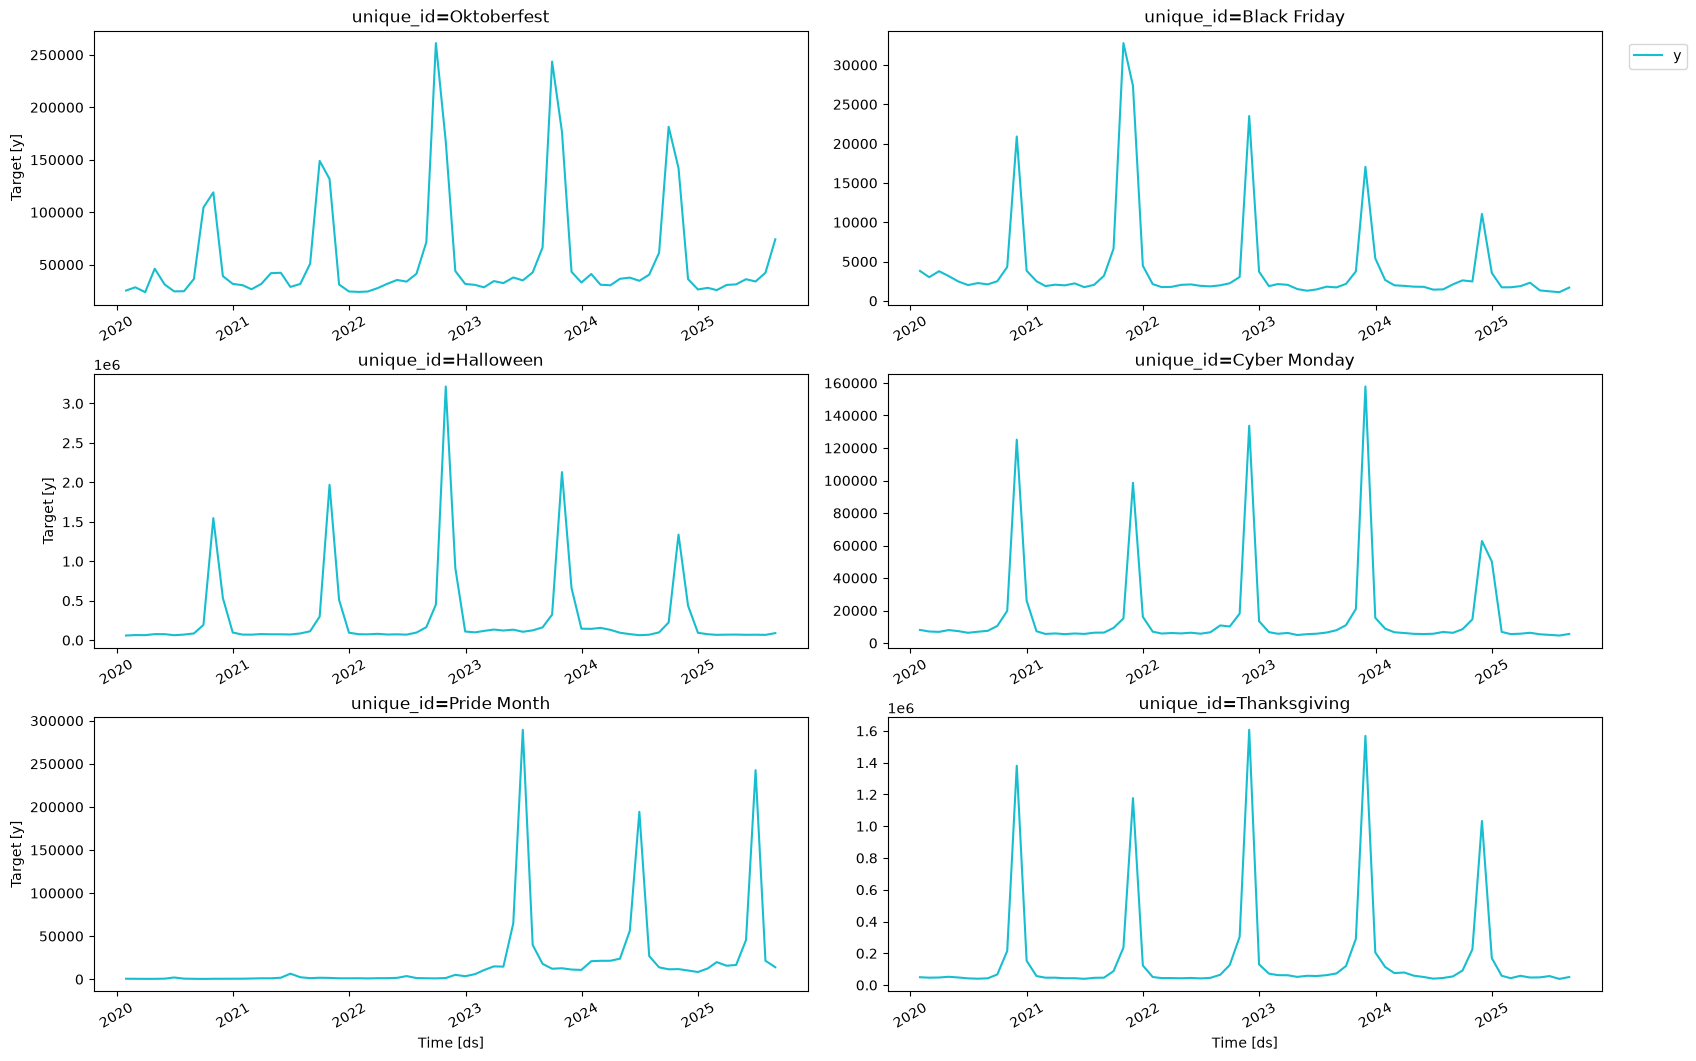

In [4]:
FoundationForecast.plot(df)


## Import the models


In [5]:
from foundationforecast.models import Simons


## Create a FoundationForecast

We compare all four Simons sizes. Each model gets a distinct `alias` so its forecasts are easy to identify.


In [6]:
models = [
    Simons(repo_id="abel-lab/Simons-25M", alias="Simons-25M", context_length=512, batch_size=2),
    Simons(repo_id="abel-lab/Simons-60M", alias="Simons-60M", context_length=512, batch_size=2),
    Simons(repo_id="abel-lab/Simons-178M", alias="Simons-178M", context_length=512, batch_size=2),
    Simons(repo_id="abel-lab/Simons-297M", alias="Simons-297M", context_length=512, batch_size=2),
]

ff = FoundationForecast(models=models)


## Generate forecast

You can optionally specify the following parameters:
- freq: The frequency of your data (e.g., 'D' for daily, 'M' for monthly)
- h: The forecast horizon, which is the number of periods to predict
- seasonality: The seasonal period of your data, which can be inferred if not provided


In [7]:
level = [20, 40, 50, 60, 80]
cv_df = ff.cross_validation(df=df, h=12, level=level)


0it [00:00, ?it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 680.95it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

 33%|███▎      | 1/3 [00:00<00:00,  6.72it/s]

100%|██████████| 3/3 [00:00<00:00, 14.49it/s]

... (29 outputs left out)

 67%|██████▋   | 2/3 [00:00<00:00, 12.69it/s]

100%|██████████| 3/3 [00:00<00:00, 13.19it/s]


1it [01:37, 97.19s/it]

1it [01:37, 97.19s/it]

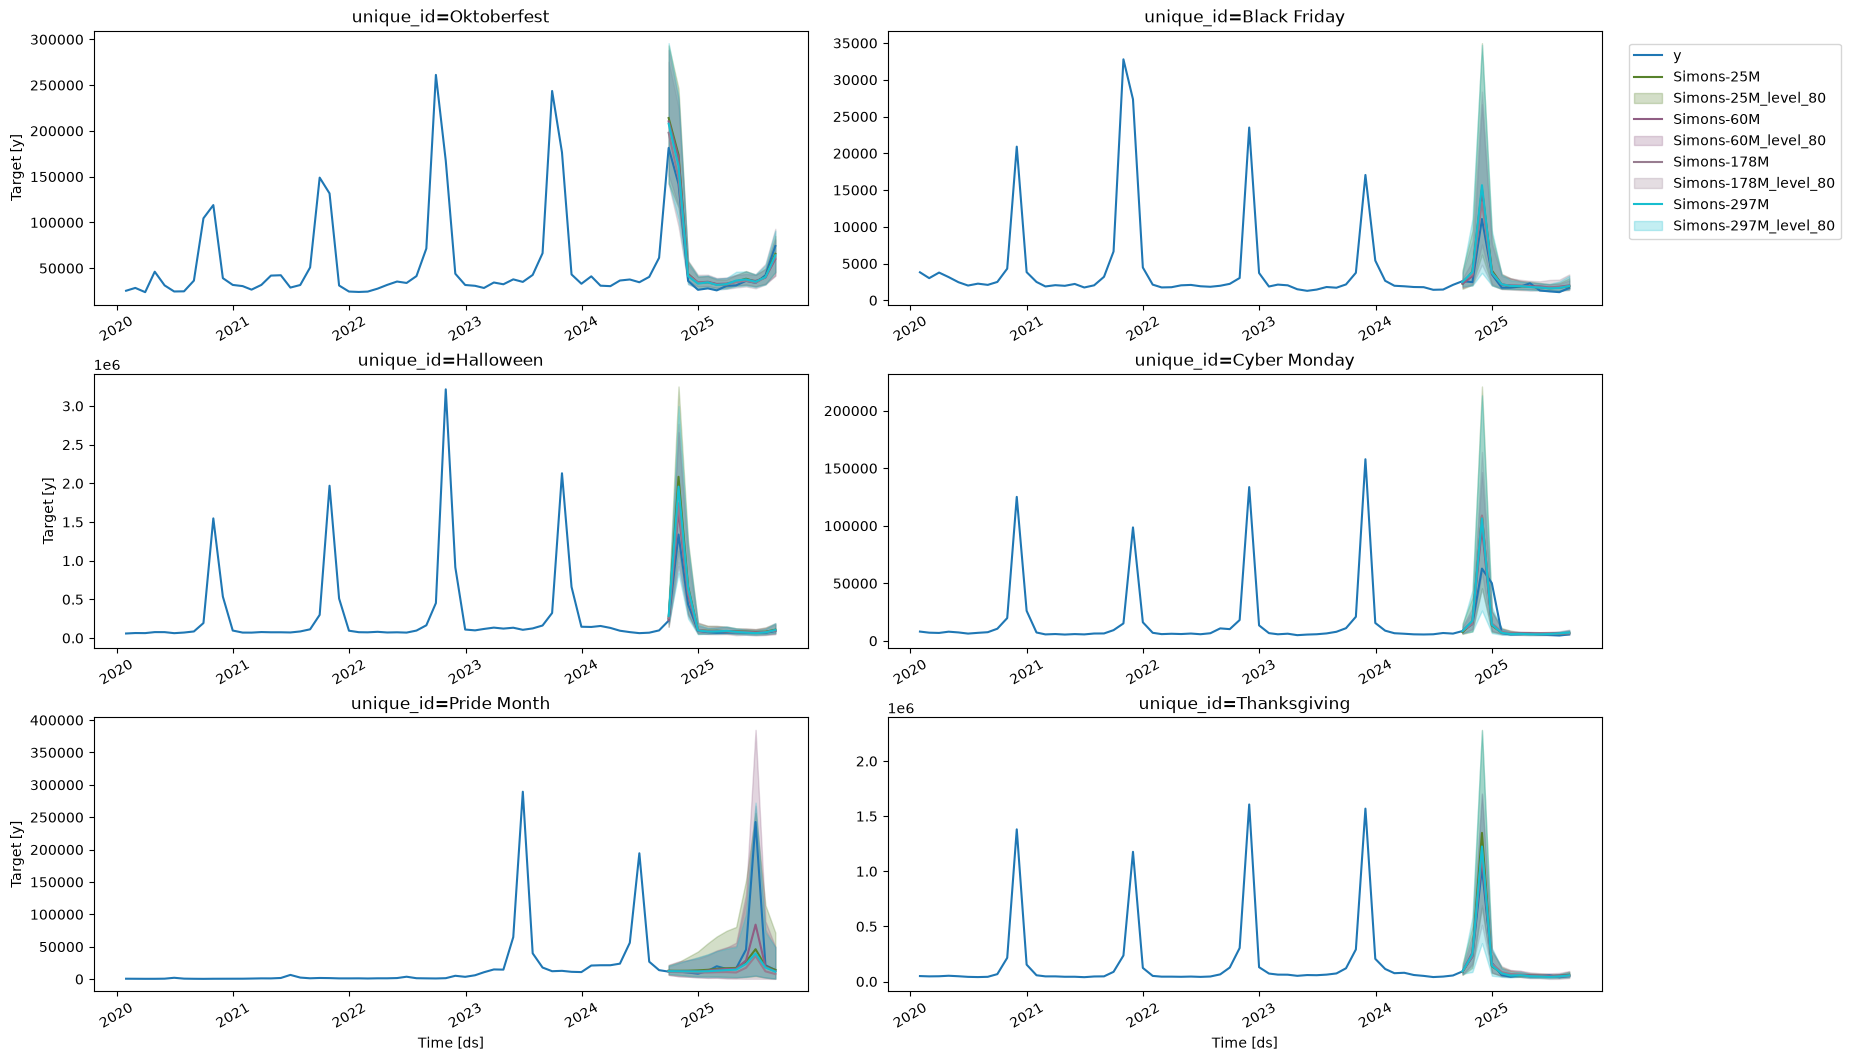

In [8]:
ff.plot(df, cv_df.drop(columns=["cutoff", "y"]), level=[80])


In [9]:
cv_df.head()


,unique_id,ds,cutoff,y,Simons-25M,Simons-25M-lo-20,Simons-25M-hi-20,Simons-25M-lo-40,Simons-25M-hi-40,Simons-25M-lo-50,...,Simons-297M-lo-20,Simons-297M-hi-20,Simons-297M-lo-40,Simons-297M-hi-40,Simons-297M-lo-50,Simons-297M-hi-50,Simons-297M-lo-60,Simons-297M-hi-60,Simons-297M-lo-80,Simons-297M-hi-80
0,Black Friday,2024-09-30,2024-08-31,2607,2236.0,2104.0,2378.0,1983.0,2554.0,1904.5,...,2334.0,2578.0,2214.0,2771.0,2181.0,2888.5,2148.0,3006.0,1920.0,3845.0
1,Black Friday,2024-10-31,2024-08-31,2470,3894.0,3354.0,4582.0,2935.0,5562.0,2747.5,...,3325.0,4507.0,3016.0,5512.0,2761.0,6364.5,2506.0,7217.0,2003.0,11057.0
2,Black Friday,2024-11-30,2024-08-31,11058,15100.0,12453.0,17945.0,10226.0,21775.0,9230.5,...,11939.0,18666.0,8444.0,21676.0,6965.5,24275.0,5487.0,26874.0,3734.0,34763.0
3,Black Friday,2024-12-31,2024-08-31,3548,4066.0,3555.0,4703.0,3049.0,5511.0,2779.0,...,3376.0,4241.0,2977.0,5142.0,2752.0,5908.5,2527.0,6675.0,2032.0,9522.0
4,Black Friday,2025-01-31,2024-08-31,1724,2159.0,1981.0,2248.0,1866.0,2465.0,1789.5,...,2052.0,2308.0,1953.0,2482.0,1872.5,2635.0,1792.0,2788.0,1588.0,3474.0


## Evaluation


In [10]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mase, scaled_crps


In [11]:
eval_df = evaluate(
    cv_df.drop(columns=["cutoff"]),
    train_df=df.query("ds <= '2024-08-31'"),
    metrics=[partial(mase, seasonality=12), scaled_crps],
    level=level,
)
eval_df.groupby("metric").mean(numeric_only=True).T.sort_values(
    by="scaled_crps"
).round(3)


metric,mase,scaled_crps
Simons-60M,0.913,0.210
Simons-178M,0.974,0.237
Simons-297M,1.065,0.259
Simons-25M,1.183,0.276
